# Lonta HVAC seasonality: source audit and descriptive analysis

## tl;dr
All **288 station-month records / 576 degree-day values** reconcile with the 24 preserved NOAA files and their SHA-256 hashes. NOAA marks 526 values Standard, 50 Representative, and 13 nonzero values rounded to zero (X).

The cooling peak is August at Dallas–Fort Worth Airport (643.0 °F-days), July at Phoenix Sky Harbor (945.4), and September at San Francisco International. The three largest cooling months contain 83.3% of Boston Logan's twelve-month cooling total and 37.0% at Miami International. **These are climate normals, not contractor jobs or a demand forecast.**

## Context & Methods
This companion checks Lonta's extraction against NOAA's monthly 1991–2020 U.S. Climate Normals, retrieved October 9, 2026. It reproduces the calculations and the public chart without making network requests.

### Key Assumptions
- Purposive selection of 24 airport reference stations; no claim of national representativeness or city-wide averages.
- Published MLY-HTDD-NORMAL and MLY-CLDD-NORMAL use a 65°F base. The original CSV numbers are already decimal °F-days.
- Missing sentinel −9999 would fail the audit, not become zero. Flags and year counts remain publisher-defined.
- The annual denominator is the sum of the twelve monthly normals; top-three share is descriptive, not a share of jobs.
- Months, heating and cooling are repeated measures, not independent stations. No pooled statistical model or confidence intervals.

Sources: [NOAA product](https://www.ncei.noaa.gov/products/land-based-station/us-climate-normals), [monthly documentation](https://www.ncei.noaa.gov/pub/data/cdo/documentation/normals-monthly-1991-2020_documentation.pdf), [CSV format](https://www.ncei.noaa.gov/data/normals-monthly/1991-2020/doc/Readme_By-Variable_By-Station_Normals_Files.txt), [NWS degree-day definition](https://www.weather.gov/key/climate_heat_cool).

Environment: Python 3.12; matplotlib, nbformat, nbclient, nbconvert and ipykernel. Execute from this notebook's directory or from web/. The raw/ files and selected.json travel beside this notebook; audit and plotting code live in ../../scripts/.


## Data
### Load and reconcile the preserved station files

In [1]:
import sys
from pathlib import Path
from IPython.display import display, HTML
import html
import matplotlib
import matplotlib.pyplot as plt

candidate_roots = [Path.cwd(), *Path.cwd().parents]
WEB = next(p for p in candidate_roots if (p / 'scripts/seasonality_audit.py').exists())
sys.path.insert(0, str(WEB / 'scripts'))
from seasonality_audit import audit, summary
from seasonality_chart import cooling_peak_figure

audit_result, cities = audit()
assert audit_result['station_months'] == 288
assert audit_result['degree_day_values'] == 576
print(audit_result)
print('Python:', sys.version.split()[0], '| Matplotlib:', matplotlib.__version__)


{'stations': 24, 'station_months': 288, 'degree_day_values': 576, 'completeness_flags': {'S': 526, 'R': 50}, 'rounded_nonzero_X': 13}
Python: 3.12.8 | Matplotlib: 3.10.8


## Results
### Check the four comparison fixtures against independent Decimal arithmetic

In [2]:
comparison = [summary(c) for c in cities if c['id'] in {'dallas-fort-worth', 'phoenix', 'boston', 'miami'}]
expected = {'Boston': (284.4, 801.8), 'Dallas–Fort Worth': (643.0, 2823.8), 'Miami': (595.2, 4656.0), 'Phoenix': (945.4, 4764.7)}
for row in comparison:
    assert (row['peak_F_days'], row['twelve_month_total_F_days']) == expected[row['city']]
headers = ['Reference city', 'Cooling peak month', 'Peak °F-days', '12-month total °F-days', 'Three-month share']
table_rows = [[r['city'], '/'.join(str(m) for m in r['peak_months']), f"{r['peak_F_days']:,.1f}", f"{r['twelve_month_total_F_days']:,.1f}", f"{r['top_three_share_percent']:.1f}%"] for r in comparison]
display(HTML('<table><thead><tr>' + ''.join('<th>'+h+'</th>' for h in headers) + '</tr></thead><tbody>' + ''.join('<tr>'+''.join('<td>'+html.escape(v)+'</td>' for v in row)+'</tr>' for row in table_rows) + '</tbody></table>'))


Reference city,Cooling peak month,Peak °F-days,12-month total °F-days,Three-month share
Boston,7,284.4,801.8,83.3%
Dallas–Fort Worth,8,643.0,"2,823.8",63.4%
Miami,8,595.2,"4,656.0",37.0%
Phoenix,7,945.4,"4,764.7",55.6%


### Compare the month of the largest cooling normal
The point position encodes month; the direct label preserves the actual monthly normal. All selected peaks fall in July–September; the chart is explicitly limited to those months. It does not rank business opportunities.

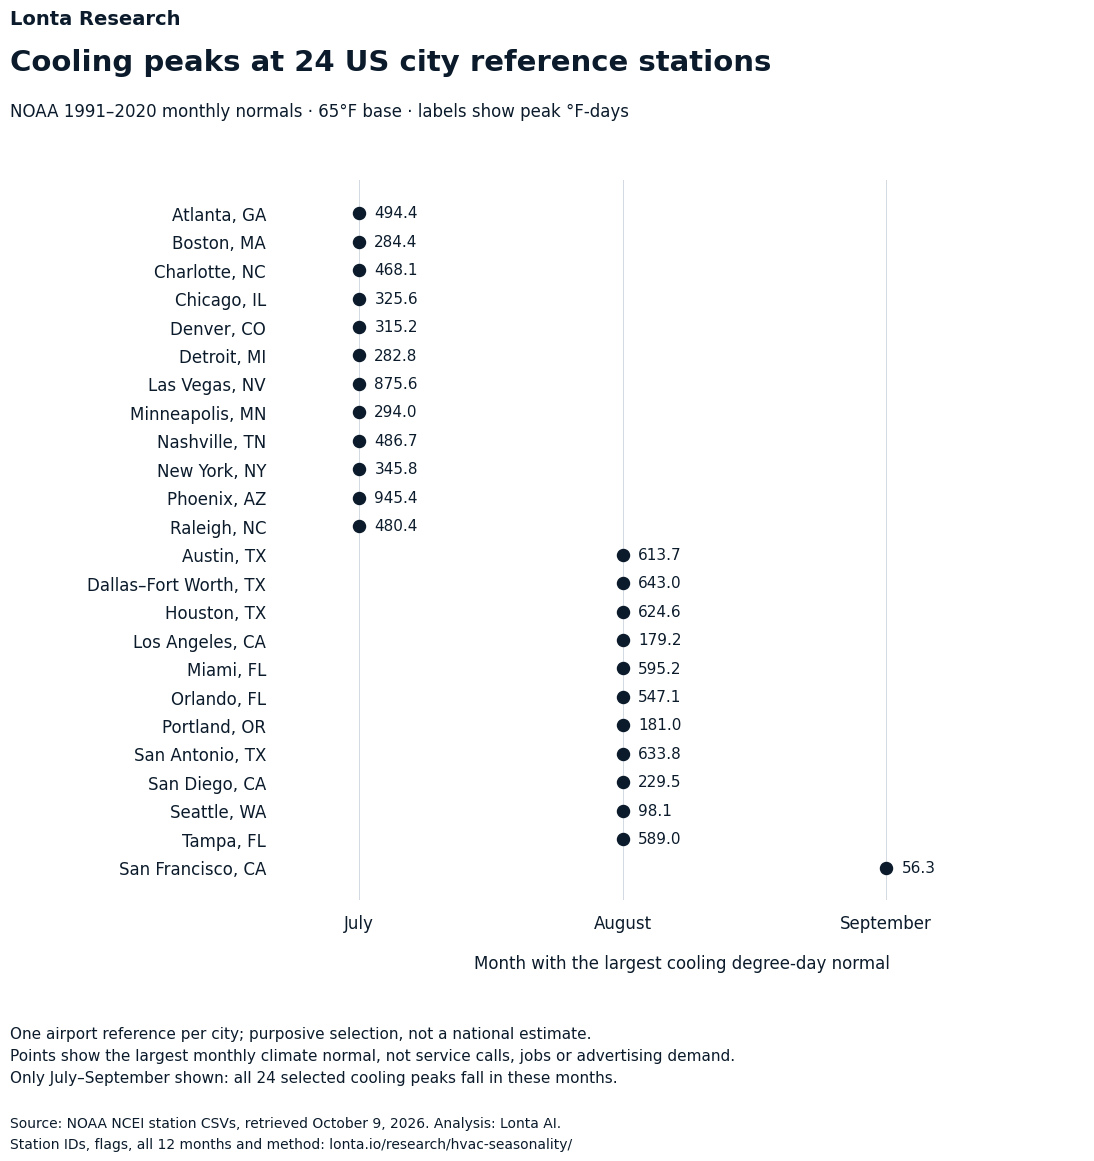

In [3]:
figure = cooling_peak_figure(cities)
display(figure)
plt.close(figure)


## Takeaways
A universal summer calendar misses local climate differences. Airport siting and the historical 1991–2020 period limit applicability to a contractor's current service area. Compare these patterns with actual jobs, capacity and current weather before changing a live account.

**Validation:** 24 original-file hashes, metadata, 12 months per station, all 576 values and their flags/year counts reconcile. The source audit checks extraction fidelity; it does not independently validate NOAA's original climate calculations. The TypeScript export/calculation tests run separately in `node scripts/seasonality-test.mjs` from web/.

Public resource: [lonta.io/research/hvac-seasonality/](https://lonta.io/research/hvac-seasonality/).